<a href="https://colab.research.google.com/github/RaidenBrooke/ENGR4182026ProjectGroup5/blob/main/ENGR418ClassProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [43]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [44]:
df = pd.read_csv("/content/drive/MyDrive/ims_1st_test_features.csv", parse_dates=["time"])

df["hours"] = (df["time"] - df["time"].iloc[0]).dt.total_seconds() / 3600

feature_cols = [c for c in df.columns if c.startswith(("rms_", "kurt_", "peak_"))]
X = df[feature_cols]
y = df["hours"]

Target: uncapped
Baseline RMSE:       235.1
Linear (Ridge) R²:   0.523
Linear (Ridge) RMSE: 162.35
Random forest R²:    0.957
Random forest RMSE:  48.77


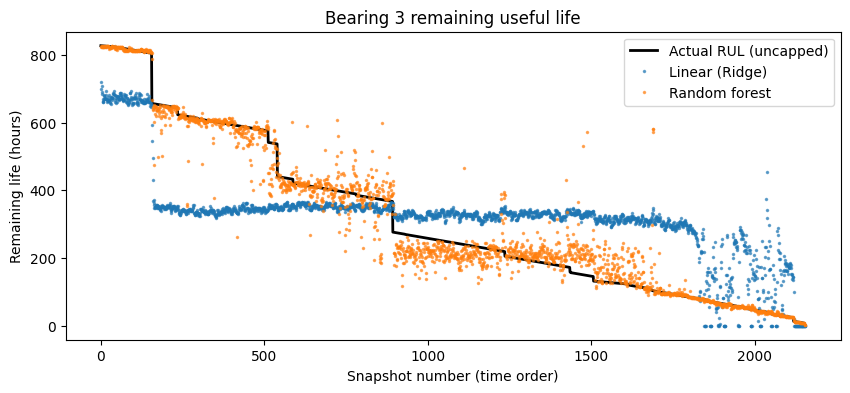

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv("/content/drive/MyDrive/ims_1st_test_features.csv", parse_dates=["time"])

# Target: remaining useful life (hours until the end of the test)
df["hours"] = (df["time"] - df["time"].iloc[0]).dt.total_seconds() / 3600
df["rul"] = df["hours"].max() - df["hours"]

CAP = None                     # set a number (e.g. 175) to cap the target
if CAP is None:
    y = df["rul"]
    upper = df["rul"].max()
    cap_label = "uncapped"
else:
    y = df["rul"].clip(upper=CAP)
    upper = CAP
    cap_label = f"capped at {CAP}"

# Pick the bearing: bearing 3 = ch5, ch6 | bearing 4 = ch7, ch8
channels = ["ch5", "ch6"]
bearing_name = "Bearing 3"
feature_cols = [f"{s}_{ch}" for ch in channels for s in ["rms", "kurt"]]

# Log of RMS (kurtosis can be negative, so it stays as is), then smooth
X = df[feature_cols].copy()
for c in X.columns:
    if c.startswith("rms_"):
        X[c] = np.log(X[c])
X = X.rolling(5, min_periods=1).mean()

lin = make_pipeline(StandardScaler(), Ridge(alpha=10))
rf = RandomForestRegressor(n_estimators=200, random_state=42)

# 5-fold cross-validation: every snapshot gets a prediction from a model
# that was trained without it
cv = KFold(n_splits=5, shuffle=True, random_state=42)
y_pred = np.clip(cross_val_predict(lin, X, y, cv=cv), 0, upper)
y_pred_rf = cross_val_predict(rf, X, y, cv=cv)

baseline = np.full(len(y), y.mean())
print(f"Target: {cap_label}")
print("Baseline RMSE:      ", round(np.sqrt(mean_squared_error(y, baseline)), 2))
print("Linear (Ridge) R²:  ", round(r2_score(y, y_pred), 3))
print("Linear (Ridge) RMSE:", round(np.sqrt(mean_squared_error(y, y_pred)), 2))
print("Random forest R²:   ", round(r2_score(y, y_pred_rf), 3))
print("Random forest RMSE: ", round(np.sqrt(mean_squared_error(y, y_pred_rf)), 2))

# Plot against snapshot number so recording gaps don't show up
idx = np.arange(len(df))
plt.figure(figsize=(10, 4))
plt.plot(idx, y, color="black", linewidth=2, label=f"Actual RUL ({cap_label})")
plt.plot(idx, y_pred, ".", markersize=3, alpha=0.6, label="Linear (Ridge)")
plt.plot(idx, y_pred_rf, ".", markersize=3, alpha=0.6, label="Random forest")
plt.xlabel("Snapshot number (time order)")
plt.ylabel("Remaining life (hours)")
plt.title(f"{bearing_name} remaining useful life")
plt.legend()
plt.show()